In [37]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.animation import FuncAnimation
from IPython import display
from tqdm import tqdm

In [19]:
DATA = Path('../data/external')
CACHE = DATA / 'cache'
cleaned_papers = pd.read_parquet(DATA / 'papers_cleaned.gencat.parquet')

In [20]:
cleaned_papers['date'] = pd.to_datetime(cleaned_papers['date'])
print(min(cleaned_papers['date'].dt.year))
print(max(cleaned_papers['date'].dt.year))

1949
2026


In [21]:
#year_df = cleaned_papers[cleaned_papers['date'].dt.year == 2021]
exploded_papers = cleaned_papers.explode('orcidResearchers')
grouped = exploded_papers['orcidResearchers'].value_counts() 
grouped

orcidResearchers
0000-0001-6571-4096    13064
0000-0001-8883-6539    12699
0000-0003-3232-4598    12234
0000-0002-7215-0150    10274
0000-0003-2700-7459    10236
                       ...  
0000-0002-1063-3675        1
0000-0002-1849-3662        1
0000-0003-2849-1801        1
0000-0002-3517-6116        1
0000-0001-7169-8002        1
Name: count, Length: 31197, dtype: int64

In [22]:
vc = grouped.value_counts().sort_index()            # counts per value, ascending x

dif = pd.DataFrame({
    "value": vc.index,
    "count": vc.values,
})
dif["cdf"]   = dif["count"].cumsum() / dif["count"].sum()
dif["surv"]  = 1 - dif["cdf"]                 # this is what you plot
# optional: "fraction >= x" instead of "> x"
dif["surv_ge"] = dif["surv"] + dif["count"] / dif["count"].sum()

In [23]:
dif

,value,count,cdf,surv,surv_ge
0,1,1182,0.037888,0.962112,1.000000
1,2,1202,0.076418,0.923582,0.962112
2,3,842,0.103407,0.896593,0.923582
3,4,898,0.132192,0.867808,0.896593
4,5,631,0.152419,0.847581,0.867808
...,...,...,...,...,...
1864,10236,1,0.999872,0.000128,0.000160
1865,10274,1,0.999904,0.000096,0.000128
1866,12234,1,0.999936,0.000064,0.000096
1867,12699,1,0.999968,0.000032,0.000064


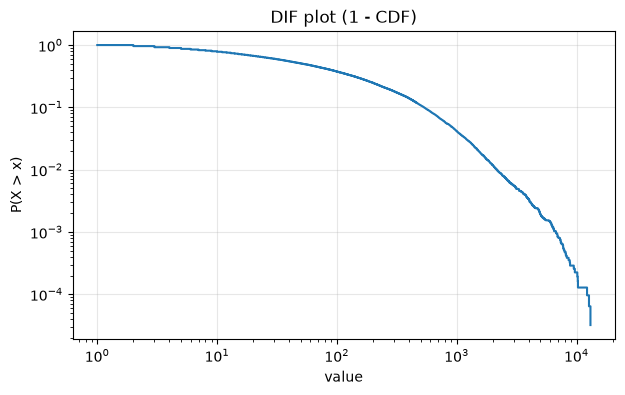

In [24]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.step(dif["value"], dif["surv_ge"], where="post")
ax.set_xlabel("value")
ax.set_ylabel("P(X > x)")
ax.set_title("DIF plot (1 - CDF)")
# ax.set_ylim(0, 1)
ax.grid(alpha=0.3)
ax.set_xscale("log")
ax.set_yscale("log")
plt.show()

In [90]:
papers_y = []
researchers_y = []
for year_paper in range(min(cleaned_papers['date'].dt.year),max(cleaned_papers['date'].dt.year)+1):
    year_df = cleaned_papers[cleaned_papers['date'].dt.year == year_paper]
    exploded_papers = year_df.explode('orcidResearchers')
    grouped = exploded_papers['orcidResearchers'].value_counts() 
    vc = grouped.value_counts().sort_index()            # counts per value, ascending x
    
    dif = pd.DataFrame({
        "value": vc.index,
        "count": vc.values,
    })
    dif["cdf"]   = dif["count"].cumsum() / dif["count"].sum()
    dif["surv"]  = 1 - dif["cdf"]                 # this is what you plot
    # optional: "fraction >= x" instead of "> x"
    dif["surv_ge"] = dif["surv"] + dif["count"] / dif["count"].sum()
    papers_y.append(dif["value"])
    researchers_y.append(dif["surv_ge"])
print(len(papers_y))
print(len(researchers_y))

78
78


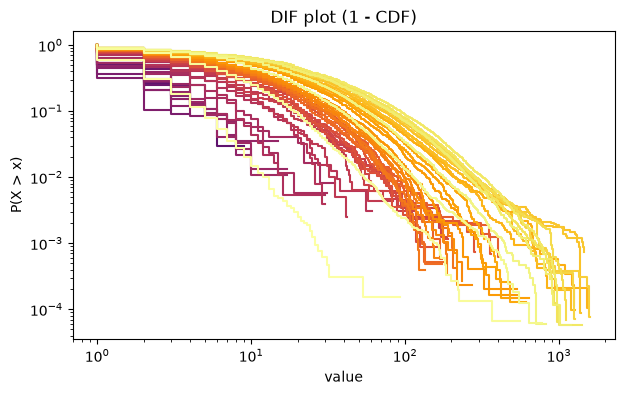

In [91]:
fig, ax = plt.subplots(figsize=(7, 4))
cmap1 = plt.get_cmap('inferno')
colors = cmap1(np.linspace(0, 1, len(papers_y)))

for i, (paper, researcher) in enumerate(zip(papers_y, researchers_y)):
    ax.step(paper, researcher, color=colors[i])
ax.set_xlabel("value")
ax.set_ylabel("P(X > x)")
ax.set_title("DIF plot (1 - CDF)")
# ax.set_ylim(0, 1)
ax.set_xscale("log")
ax.set_yscale("log")
plt.show()

In [87]:
papers_y = []
researchers_y = []
areas = []

for year_paper in range(
    cleaned_papers['date'].dt.year.min(),
    cleaned_papers['date'].dt.year.max() + 1
):
    year_df = cleaned_papers[
        cleaned_papers['date'].dt.year == year_paper
    ]

    exploded_papers = year_df.explode('orcidResearchers')
    grouped = exploded_papers['orcidResearchers'].value_counts()
    vc = grouped.value_counts().sort_index()

    dif = pd.DataFrame({
        "value": vc.index,
        "count": vc.values,
    })

    dif["cdf"] = dif["count"].cumsum() / dif["count"].sum()
    dif["surv"] = 1 - dif["cdf"]
    dif["surv_ge"] = dif["surv"] + dif["count"] / dif["count"].sum()

    x = dif["value"].to_numpy(dtype=float)
    y = dif["surv_ge"].to_numpy(dtype=float)

    # Area under the curve
    area = np.trapezoid(y, x)

    # Normalize so area = 1
    if area > 0:
        y_norm = y / area
    else:
        y_norm = y

    papers_y.append(x)
    researchers_y.append(y_norm)
    areas.append(area)

print(len(papers_y))
print(len(researchers_y))
#print("Original areas:", areas)

78
78
Original areas: [np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.75), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(3.0), np.float64(2.161764705882353), np.float64(0.0), np.float64(1.125), np.float64(1.5714285714285716), np.float64(1.75), np.float64(1.1818181818181819), np.float64(0.868421052631579), np.float64(1.4583333333333335), np.float64(1.2272727272727273), np.float64(1.826086956521739), np.float64(2.4107142857142856), np.float64(2.135135135135135), np.float64(2.2282608695652177), np.float64(3.4385245901639347), np.float64(3.4040697674418605), np.float64(3.5054347826086962), np.float64(4.52156862745098), np.float64(5.447368421052632), np.float64(5.4664179104477615), np.float64(6.780042918454936), np.float64(7.616239316239316)

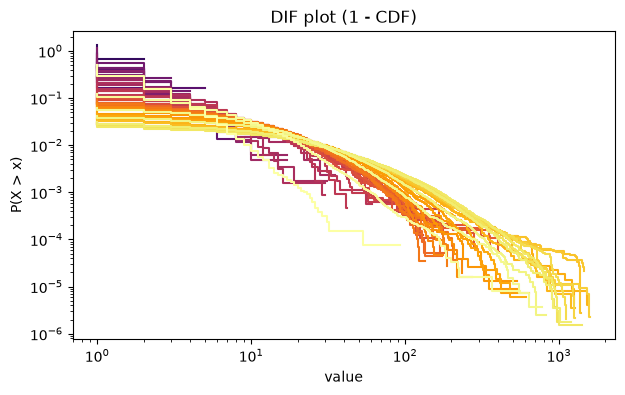

In [88]:
fig, ax = plt.subplots(figsize=(7, 4))
cmap1 = plt.get_cmap('inferno')
colors = cmap1(np.linspace(0, 1, len(papers_y)))

for i, (paper, researcher) in enumerate(zip(papers_y, researchers_y)):
    ax.step(paper, researcher, color=colors[i])
ax.set_xlabel("value")
ax.set_ylabel("P(X > x)")
ax.set_title("DIF plot (1 - CDF)")
# ax.set_ylim(0, 1)
ax.set_xscale("log")
ax.set_yscale("log")
plt.show()